## 0. Setup and reproducibility

In [1]:
import math, time, copy, hashlib, os, json, random, platform
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, pandas as pd
from sklearn.metrics import confusion_matrix
torch.set_num_threads(2)

GLOBAL_SEED = 42            # data split + test-set corruption use fixed seeds derived from this
SEEDS       = [0, 1, 2]     # the 3 training seeds reported everywhere as mean ± std
random.seed(GLOBAL_SEED); np.random.seed(GLOBAL_SEED); torch.manual_seed(GLOBAL_SEED)
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3,'font.size':10})
print('python',platform.python_version(),'| torch',torch.__version__,'| seed',GLOBAL_SEED,'| training seeds',SEEDS)

python 3.13.16 | torch 2.14.1+cu130 | seed 42 | training seeds [0, 1, 2]


In [2]:
CLASSES=['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
MEAN=torch.tensor([0.4914,0.4822,0.4465]).view(1,3,1,1); STD=torch.tensor([0.2470,0.2435,0.2616]).view(1,3,1,1)

## 1. Data
`load_cifar()` uses torchvision's CIFAR-10 download and falls back to a local `.npz` copy if there is no internet. To make the split independent of how the files are ordered on disk, I sort the images by a hash of their pixel content before sampling, so everyone gets exactly the same 500 images for the same seed.

In [3]:
def load_cifar():
    try:
        from torchvision.datasets import CIFAR10
        tr = CIFAR10('./data', train=True, download=True); te = CIFAR10('./data', train=False, download=True)
        out = (tr.data, np.array(tr.targets), te.data, np.array(te.targets)); src = 'torchvision'
    except Exception as e:
        print('torchvision download failed (', type(e).__name__, ') -> using local npz copy')
        a = np.load('cifar_train.npz'); b = np.load('cifar_test.npz')
        out = (a['x'], a['y'], b['x'], b['y']); src = 'local npz'
    return out + (src,)

def canonical(x, y):
    # order images by sha1 of their bytes -> identical order whatever the source / file order was
    order = np.argsort([hashlib.sha1(i.tobytes()).hexdigest() for i in x])
    return x[order], y[order]

xtr_all, ytr_all, xte_all, yte_all, SRC = load_cifar()
xtr_all, ytr_all = canonical(xtr_all, ytr_all); xte_all, yte_all = canonical(xte_all, yte_all)
print('source:', SRC, '| full train', xtr_all.shape, '| test', xte_all.shape)

def to_t(x): return torch.tensor(x).permute(0,3,1,2).float().div(255)

# 50 images per class (fixed seed), then a stratified 40/10 per class split -> 400 train / 100 val
rng = np.random.RandomState(GLOBAL_SEED); tr_idx, va_idx = [], []
for c in range(10):
    idx = rng.choice(np.where(ytr_all == c)[0], 50, replace=False)
    tr_idx += list(idx[:40]); va_idx += list(idx[40:])
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)
Xtr, Ytr = to_t(xtr_all[tr_idx]), torch.tensor(ytr_all[tr_idx])
Xva, Yva = to_t(xtr_all[va_idx]), torch.tensor(ytr_all[va_idx])
Xclean, Yclean = to_t(xte_all), torch.tensor(yte_all)
print('train_small -> train', tuple(Xtr.shape), 'val', tuple(Xva.shape), '| per-class train', torch.bincount(Ytr).tolist(), 'val', torch.bincount(Yva).tolist())

torchvision download failed ( URLError ) -> using local npz copy


source: local npz | full train (50000, 32, 32, 3) | test (10000, 32, 32, 3)
train_small -> train (400, 3, 32, 32) val (100, 3, 32, 32) | per-class train [40, 40, 40, 40, 40, 40, 40, 40, 40, 40] val [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]


## 2. Image operations and the shifted test set
First the batched image operations (rotation, brightness/contrast, blur, occlusion, ...). Then the seeded pipeline that builds `shifted_test` from the clean test images. This pipeline is used **only to build the test set**; the training augmentation (section 4) is written separately and deliberately does not contain the hidden corruption.

In [4]:
# ---------- generic image ops (batched, inputs in [0,1], shape B,3,H,W) ----------
def gray(x): return (0.299*x[:,0:1]+0.587*x[:,1:2]+0.114*x[:,2:3])
def affine(x, angle_deg, scale=None, shift=None):
    B=x.shape[0]; a=angle_deg*math.pi/180
    s=torch.ones(B) if scale is None else scale
    cos,sin=torch.cos(a)/s,torch.sin(a)/s
    theta=torch.zeros(B,2,3); theta[:,0,0]=cos; theta[:,0,1]=-sin; theta[:,1,0]=sin; theta[:,1,1]=cos
    if shift is not None: theta[:,:,2]=shift
    grid=F.affine_grid(theta,x.shape,align_corners=False)
    return F.grid_sample(x,grid,mode='bilinear',padding_mode='zeros',align_corners=False)
def brightness_contrast(x,b,c):
    m=x.mean(dim=(1,2,3),keepdim=True)
    return ((x-m)*c.view(-1,1,1,1)+m).mul(b.view(-1,1,1,1)).clamp(0,1)
def saturation(x,s):
    g=gray(x); return (g+(x-g)*s.view(-1,1,1,1)).clamp(0,1)
def gaussian_blur(x,sigma,k=5):
    B,C,H,W=x.shape
    r=torch.arange(k).float()-k//2
    ker=torch.exp(-(r.view(1,-1)**2)/(2*sigma.view(-1,1)**2)); ker=ker/ker.sum(1,keepdim=True)
    ker=ker.repeat_interleave(C,0)                                  # (B*C,k)
    y=x.reshape(1,B*C,H,W)
    y=F.conv2d(F.pad(y,(k//2,k//2,0,0),mode='reflect'),ker.view(B*C,1,1,k),groups=B*C)
    y=F.conv2d(F.pad(y,(0,0,k//2,k//2),mode='reflect'),ker.view(B*C,1,k,1),groups=B*C)
    return y.reshape(B,C,H,W)
def rect_mask(B,H,W,area,aspect,gen):
    """boolean mask (B,1,H,W), True inside a random rectangle of the given area fraction"""
    h=(torch.sqrt(area*H*W*aspect)).round().clamp(1,H); w=(torch.sqrt(area*H*W/aspect)).round().clamp(1,W)
    top=(torch.rand(B,generator=gen)*(H-h+1)).floor(); left=(torch.rand(B,generator=gen)*(W-w+1)).floor()
    ys=torch.arange(H).view(1,H,1); xs=torch.arange(W).view(1,1,W)
    m=(ys>=top.view(-1,1,1))&(ys<(top+h).view(-1,1,1))&(xs>=left.view(-1,1,1))&(xs<(left+w).view(-1,1,1))
    return m.unsqueeze(1)
def U(n,lo,hi,gen): return lo+(hi-lo)*torch.rand(n,generator=gen)

In [5]:
# ---------- simulated hidden-test pipeline (fixed + seeded; only used to BUILD test sets) ----------
PERMS=torch.tensor([[0,2,1],[1,0,2],[1,2,0],[2,0,1],[2,1,0]])
def channel_swap(x,p,gen):
    B=x.shape[0]; do=torch.rand(B,generator=gen)<p
    perm=PERMS[torch.randint(0,5,(B,),generator=gen)]; perm[~do]=torch.tensor([0,1,2])
    return x[torch.arange(B).view(-1,1),perm], do
def make_shifted(x,seed,hidden=True,extras=True):
    g=torch.Generator().manual_seed(seed); B=x.shape[0]; info={}
    ang=U(B,-25,25,g); y=affine(x,ang); info['rot']=ang
    br=U(B,0.5,1.5,g); co=U(B,0.5,1.5,g); y=brightness_contrast(y,br,co); info['bright']=br; info['contrast']=co
    if hidden: y,sw=channel_swap(y,0.5,g); info['swap']=sw
    if extras:
        bl=torch.rand(B,generator=g)<0.4; sg=U(B,0.5,1.5,g)
        yb=gaussian_blur(y,sg); y=torch.where(bl.view(-1,1,1,1),yb,y); info['blur']=bl
        nz=torch.rand(B,generator=g)<0.4; sd=U(B,0.02,0.08,g)
        yn=(y+torch.randn(y.shape,generator=g)*sd.view(-1,1,1,1)).clamp(0,1); y=torch.where(nz.view(-1,1,1,1),yn,y); info['noise']=nz
    area=U(B,0.18,0.32,g); asp=torch.exp(U(B,math.log(0.5),math.log(2),g))
    m=rect_mask(B,32,32,area,asp,g); y=y.masked_fill(m,0.0); info['occ_area']=m.float().mean((1,2,3))
    return y.contiguous(),info

built shifted_test from the clean test set (seed 2026)
shifted_test (10000, 3, 32, 32) | mean occluded area 25.0%


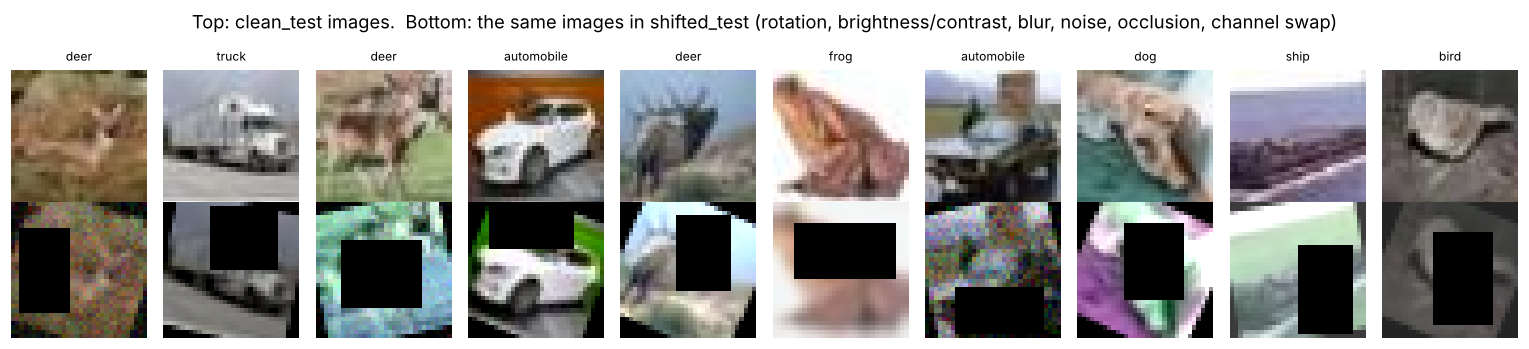

validation-shift proxy: (1000, 3, 32, 32)


In [6]:
if os.path.exists('shifted_test.npz'):
    d = np.load('shifted_test.npz'); Xshift = to_t(d['x']); Yshift = torch.tensor(d['y']); INFO = None
    print('using the official shifted_test.npz provided next to the notebook')
else:
    Xshift, INFO = make_shifted(Xclean, seed=2026); Yshift = Yclean.clone()
    print('built shifted_test from the clean test set (seed 2026)')
print('shifted_test', tuple(Xshift.shape), '| mean occluded area %.1f%%' % (100*INFO['occ_area'].mean()) if INFO else '')

fig, ax = plt.subplots(2, 10, figsize=(14, 3.2))
for j in range(10):
    ax[0,j].imshow(Xclean[j].permute(1,2,0)); ax[1,j].imshow(Xshift[j].permute(1,2,0))
    ax[0,j].set_title(CLASSES[Yclean[j]], fontsize=8); ax[0,j].axis('off'); ax[1,j].axis('off')
fig.suptitle('Top: clean_test images.  Bottom: the same images in shifted_test (rotation, brightness/contrast, blur, noise, occlusion, channel swap)')
plt.tight_layout(); plt.show()

# a small proxy of the shift, made ONLY from the 100 validation images (10 differently-corrupted copies each, own seed).
# It is used for hyper-parameter selection so that we never need to touch shifted_test.
Xva_shift, _ = make_shifted(Xva.repeat(10,1,1,1), seed=777, hidden=False); Yva_shift = Yva.repeat(10)
print('validation-shift proxy:', tuple(Xva_shift.shape))

## 3. Model: LeNet-style stem, three Inception modules, global average pooling
* a LeNet/AlexNet-style block first (3×3 conv + BN + ReLU, max-pool),
* three **Inception modules** (parallel 1×1, 1×1→3×3, 1×1→5×5 and pool→1×1 branches, concatenated), with max-pooling between them,
* **global average pooling** instead of big fully connected layers (fewer parameters, less to overfit),
* a small head `FC(160→128) → ReLU → Dropout → FC(128→10)`.

Input normalisation is inside the model, so the augmentations work on plain [0,1] images.

In [7]:
# ---------- model: LeNet-style stem + 3 Inception modules + GAP + small FC head ----------
class ConvBNReLU(nn.Sequential):
    def __init__(s,i,o,k): super().__init__(nn.Conv2d(i,o,k,padding=k//2,bias=False),nn.BatchNorm2d(o),nn.ReLU(inplace=True))
class Inception(nn.Module):
    def __init__(s,i,b1,r3,b3,r5,b5,bp):
        super().__init__()
        s.b1=ConvBNReLU(i,b1,1)
        s.b3=nn.Sequential(ConvBNReLU(i,r3,1),ConvBNReLU(r3,b3,3))
        s.b5=nn.Sequential(ConvBNReLU(i,r5,1),ConvBNReLU(r5,b5,5))
        s.bp=nn.Sequential(nn.MaxPool2d(3,1,1),ConvBNReLU(i,bp,1))
        s.out=b1+b3+b5+bp
    def forward(s,x): return torch.cat([s.b1(x),s.b3(x),s.b5(x),s.bp(x)],1)
class Net(nn.Module):
    def __init__(s,drop=0.5):
        super().__init__()
        s.stem=nn.Sequential(ConvBNReLU(3,32,3),nn.MaxPool2d(2))                 # 32->16
        s.i1=Inception(32,16,16,32,8,8,8)                                         # 64 ch
        s.p1=nn.MaxPool2d(2)                                                      # 16->8
        s.i2=Inception(64,32,24,48,8,16,16)                                       # 112 ch
        s.p2=nn.MaxPool2d(2)                                                      # 8->4
        s.i3=Inception(112,48,32,64,12,24,24)                                     # 160 ch
        s.gap=nn.AdaptiveAvgPool2d(1)
        s.fc1=nn.Linear(160,128); s.drop=nn.Dropout(drop); s.fc2=nn.Linear(128,10)
        s.register_buffer('mean',MEAN); s.register_buffer('std',STD)
    def forward(s,x):
        x=(x-s.mean)/s.std
        x=s.p2(s.i2(s.p1(s.i1(s.stem(x))))); x=s.i3(x)
        x=s.gap(x).flatten(1)
        return s.fc2(s.drop(F.relu(s.fc1(x))))
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

In [8]:
net = Net()
print(net)
print('\nTrainable parameters:', f'{n_params(net):,}')
assert n_params(net) <= 1_000_000, 'parameter budget exceeded'
assert any(isinstance(m, Inception) for m in net.modules()), 'needs an Inception module'
print('OK: <= 1,000,000 parameters and contains', sum(isinstance(m, Inception) for m in net.modules()), 'Inception modules')

Net(
  (stem): Sequential(
    (0): ConvBNReLU(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (i1): Inception(
    (b1): ConvBNReLU(
      (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (b3): Sequential(
      (0): ConvBNReLU(
        (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): ConvBNReLU(
        (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        

## 4. Augmentation (on the fly, training batches only) and the training loop
`augment()` is called on every mini-batch inside the training loop, so each epoch sees different versions of the same 400 images, and nothing is stored. The validation and test images are never augmented.

Training details (all choices justified in Part C): AdamW, 3 warm-up epochs then cosine decay, batch size 32, max 60 epochs, label smoothing and Mixup as options, and **early stopping**: I keep the weights of the epoch with the best *validation* accuracy and stop if it does not improve for 20 epochs.

In [9]:
# ---------- on-the-fly training augmentation ----------
class AugCfg:
    def __init__(s,**k):
        s.vflip=0.0; s.chswap=0.0; s.geometric=False; s.photometric=False; s.cutout=False; s.mixup=False
        s.rot=20.; s.scale=0.1; s.pad=4; s.flip=True
        s.jit=0.4; s.gray_p=0.1; s.blur_p=0.3; s.noise_p=0.3; s.noise_max=0.06
        s.cut_p=0.5; s.cut_max=0.3; s.mix_alpha=0.3; s.smooth=0.0
        s.__dict__.update(k)
    def __repr__(s): return str({k:v for k,v in s.__dict__.items()})
def random_crop(x,pad,gen):
    B,C,H,W=x.shape; xp=F.pad(x,(pad,)*4,mode='reflect')
    oy=torch.randint(0,2*pad+1,(B,),generator=gen); ox=torch.randint(0,2*pad+1,(B,),generator=gen)
    iy=oy.view(-1,1)+torch.arange(H).view(1,-1); ix=ox.view(-1,1)+torch.arange(W).view(1,-1)
    return xp[torch.arange(B).view(-1,1,1,1),torch.arange(C).view(1,-1,1,1),iy.view(B,1,H,1),ix.view(B,1,1,W)]
def augment(x,c,gen):
    B=x.shape[0]
    if c.geometric:
        x=random_crop(x,c.pad,gen)
        if c.flip:
            f=torch.rand(B,generator=gen)<0.5; x=torch.where(f.view(-1,1,1,1),x.flip(3),x)
        if c.vflip>0:
            f=torch.rand(B,generator=gen)<c.vflip; x=torch.where(f.view(-1,1,1,1),x.flip(2),x)
        x=affine(x,U(B,-c.rot,c.rot,gen),scale=U(B,1-c.scale,1+c.scale,gen))
    if c.photometric:
        x=brightness_contrast(x,U(B,1-c.jit,1+c.jit,gen),U(B,1-c.jit,1+c.jit,gen))
        x=saturation(x,U(B,1-c.jit,1+c.jit,gen))
        gm=torch.rand(B,generator=gen)<c.gray_p; x=torch.where(gm.view(-1,1,1,1),gray(x).expand(-1,3,-1,-1),x)
        bl=torch.rand(B,generator=gen)<c.blur_p; x=torch.where(bl.view(-1,1,1,1),gaussian_blur(x,U(B,0.3,1.2,gen)),x)
        nz=torch.rand(B,generator=gen)<c.noise_p
        x=torch.where(nz.view(-1,1,1,1),(x+torch.randn(x.shape,generator=gen)*U(B,0,c.noise_max,gen).view(-1,1,1,1)).clamp(0,1),x)
    if c.chswap>0:
        x,_=channel_swap(x,c.chswap,gen)
    if c.cutout:
        m=rect_mask(B,32,32,U(B,0.04,c.cut_max,gen),torch.exp(U(B,math.log(0.5),math.log(2),gen)),gen)
        m=m&(torch.rand(B,1,1,1,generator=gen)<c.cut_p)
        x=torch.where(m,torch.rand(B,3,1,1,generator=gen).expand_as(x),x)   # random-colour fill
    return x

def scaled(c,k):
    """copy of an AugCfg with every augmentation magnitude multiplied by k (k=1 -> unchanged)"""
    n=copy.copy(c); n.rot=c.rot*k; n.scale=min(c.scale*k,0.5); n.pad=max(1,round(c.pad*k)); n.jit=min(c.jit*k,0.9)
    n.gray_p=min(c.gray_p*k,0.5); n.noise_max=c.noise_max*k; n.cut_max=min(c.cut_max*k,0.8); return n

In [10]:
@torch.no_grad()
def predict(m,x,bs=1000):
    m.eval(); return torch.cat([F.softmax(m(x[i:i+bs]),1) for i in range(0,len(x),bs)])
def acc(m,x,y): return (predict(m,x).argmax(1)==y).float().mean().item()

def train_run(xtr,ytr,xva,yva,cfg,seed,epochs=60,bs=32,lr=3e-3,wd=5e-4,drop=0.5,patience=20,warm=3,verbose=False):
    torch.manual_seed(seed); np.random.seed(seed)
    gen=torch.Generator().manual_seed(seed)
    m=Net(drop); opt=torch.optim.AdamW(m.parameters(),lr=lr,weight_decay=wd)
    steps_per=math.ceil(len(xtr)/bs); total=epochs*steps_per; wsteps=warm*steps_per
    sched=torch.optim.lr_scheduler.LambdaLR(opt,lambda t: (t+1)/wsteps if t<wsteps else 0.5*(1+math.cos(math.pi*(t-wsteps)/max(1,total-wsteps))))
    hist={k:[] for k in ['train_loss','train_acc','val_loss','val_acc']}
    best=(-1,1e9); best_state=None; best_ep=0; bad=0
    for ep in range(epochs):
        m.train(); perm=torch.randperm(len(xtr),generator=gen); run=0.
        for i in range(0,len(xtr),bs):
            idx=perm[i:i+bs]
            if len(idx)<2: continue
            xb=augment(xtr[idx],cfg,gen); yb=F.one_hot(ytr[idx],10).float()
            if cfg.mixup:
                lam=float(np.random.beta(cfg.mix_alpha,cfg.mix_alpha)); j=torch.randperm(len(idx),generator=gen)
                xb=lam*xb+(1-lam)*xb[j]; yb=lam*yb+(1-lam)*yb[j]
            if cfg.smooth>0: yb=yb*(1-cfg.smooth)+cfg.smooth/10
            loss=-(yb*F.log_softmax(m(xb),1)).sum(1).mean()
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); run+=loss.item()*len(idx)
        hist['train_loss'].append(run/len(xtr))
        with torch.no_grad():
            pt=predict(m,xtr); pv=predict(m,xva)
            hist['train_acc'].append((pt.argmax(1)==ytr).float().mean().item())
            vl=F.nll_loss(pv.clamp_min(1e-8).log(),yva).item(); va=(pv.argmax(1)==yva).float().mean().item()
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if (va>best[0]) or (va==best[0] and vl<best[1]):
            best=(va,vl); best_state=copy.deepcopy(m.state_dict()); best_ep=ep; bad=0
        else: bad+=1
        if verbose: print(ep,round(hist['train_loss'][-1],3),hist['train_acc'][-1],va)
        if bad>=patience: break
    m.load_state_dict(best_state); m.eval()
    hist['best_epoch']=best_ep+1; hist['epochs_run']=len(hist['val_acc'])
    return m,hist

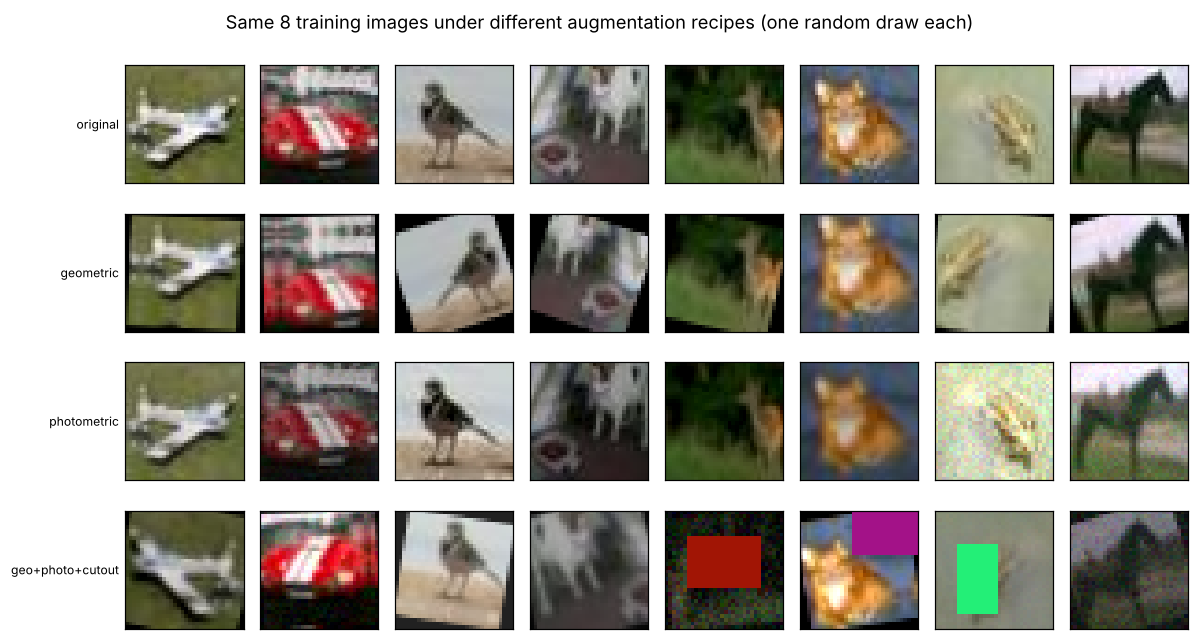

In [11]:
# quick look at what the on-the-fly augmentation does to the same 8 training images
g = torch.Generator().manual_seed(0)
rows = {
 'original': AugCfg(),
 'geometric': AugCfg(geometric=True),
 'photometric': AugCfg(photometric=True),
 'geo+photo+cutout': AugCfg(geometric=True, photometric=True, cutout=True),
}
fig, ax = plt.subplots(len(rows), 8, figsize=(11, 6))
for r, (name, cfg) in enumerate(rows.items()):
    xb = augment(Xtr[[0,40,80,120,160,200,240,280]], cfg, g)
    for j in range(8):
        ax[r,j].imshow(xb[j].permute(1,2,0).clamp(0,1)); ax[r,j].set_xticks([]); ax[r,j].set_yticks([])
    ax[r,0].set_ylabel(name, rotation=0, ha='right', va='center', fontsize=8)
fig.suptitle('Same 8 training images under different augmentation recipes (one random draw each)')
plt.tight_layout(); plt.show()

### Helpers for running experiments
* `run_config()` trains one configuration for several seeds and stores accuracy on train, validation, clean test and shifted test. The test accuracies are only **recorded** – no decision in this notebook is based on them.
* `val_score()` is used for all tuning. It trains with other seeds (100, 101) and reports accuracy on the clean validation images and on the validation-shift proxy (made only from the 100 validation images).

In [12]:
RES = {}
def run_config(name, cfg, seeds=SEEDS, **hp):
    out = []
    for s in seeds:
        t0 = time.time(); m, h = train_run(Xtr, Ytr, Xva, Yva, cfg, s, **hp)
        r = dict(seed=s, model=m, hist=h, train=acc(m, Xtr, Ytr), val=acc(m, Xva, Yva),
                 clean=acc(m, Xclean, Yclean), shifted=acc(m, Xshift, Yshift), cfg=cfg, hp=hp)
        out.append(r)
        print(f"[{name}] seed {s}: best epoch {h['best_epoch']:>2}/{h['epochs_run']:>2} | train {r['train']:.3f} val {r['val']:.3f} "
              f"clean {r['clean']:.3f} shifted {r['shifted']:.3f} | {time.time()-t0:.0f}s")
    RES[name] = out
    return out

VAL_CACHE = {}
def val_score(label, cfg, seeds=(100, 101), **hp):
    key = (repr(cfg), repr(sorted({**dict(wd=5e-4, drop=0.5), **hp}.items())), tuple(seeds))   # same setting -> reuse the earlier run
    if key not in VAL_CACHE:
        v, vs = [], []
        for s in seeds:
            m, h = train_run(Xtr, Ytr, Xva, Yva, cfg, s, **hp)
            v.append(acc(m, Xva, Yva)); vs.append(acc(m, Xva_shift, Yva_shift))
        VAL_CACHE[key] = dict(label=label, val_clean=np.mean(v), val_shift=np.mean(vs), score=(np.mean(v)+np.mean(vs))/2)
        r = VAL_CACHE[key]; print(f"{label:<34} val clean {r['val_clean']:.3f} | val shifted-proxy {r['val_shift']:.3f} | score {r['score']:.3f}")
    return dict(VAL_CACHE[key], label=label)

def mean_std(vals): return f"{100*np.mean(vals):.1f} ± {100*np.std(vals):.1f}"

## Part A – Baseline: no augmentation
Same network, same training loop, but the 400 training images are fed as they are (no augmentation, no label smoothing). Three seeds.

In [13]:
cfg_none = AugCfg()
run_config('No augmentation', cfg_none)
R = RES['No augmentation']; f1 = lambda v: f'{100*v:.1f}'
dfA = pd.DataFrame([dict(Seed=r['seed'], Train=f1(r['train']), Val=f1(r['val']), Clean_test=f1(r['clean']), Shifted_test=f1(r['shifted'])) for r in R]).set_index('Seed')
dfA.loc['mean ± std'] = [mean_std([r[k] for r in R]) for k in ['train', 'val', 'clean', 'shifted']]
print('Accuracy (%) of the no-augmentation baseline'); display(dfA)

[No augmentation] seed 0: best epoch 32/52 | train 1.000 val 0.400 clean 0.426 shifted 0.151 | 42s


[No augmentation] seed 1: best epoch 26/46 | train 0.990 val 0.370 clean 0.395 shifted 0.152 | 38s


[No augmentation] seed 2: best epoch 38/58 | train 1.000 val 0.500 clean 0.410 shifted 0.156 | 39s
Accuracy (%) of the no-augmentation baseline


,Train,Val,Clean_test,Shifted_test
Seed,,,,
0,100.0,40.0,42.6,15.1
1,99.0,37.0,39.5,15.2
2,100.0,50.0,41.0,15.6
mean ± std,99.7 ± 0.5,42.3 ± 5.6,41.0 ± 1.3,15.3 ± 0.2


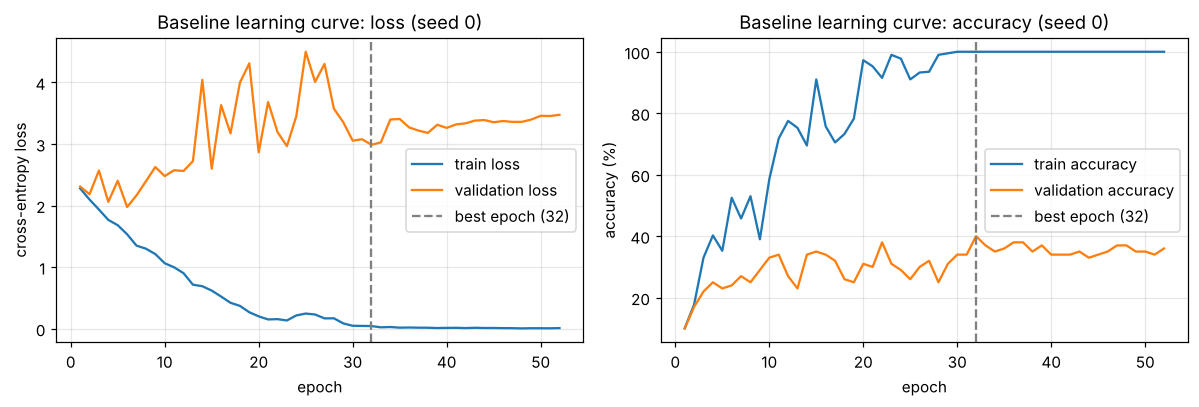

gap clean -> shifted test (mean): 25.8 points
gap train -> val   (mean): 57.3 points


In [14]:
h = RES['No augmentation'][0]['hist']; ep = np.arange(1, len(h['val_acc'])+1); be = h['best_epoch']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ep, h['train_loss'], label='train loss'); ax[0].plot(ep, h['val_loss'], label='validation loss')
ax[0].axvline(be, ls='--', c='gray', label=f'best epoch ({be})'); ax[0].set(xlabel='epoch', ylabel='cross-entropy loss', title='Baseline learning curve: loss (seed 0)'); ax[0].legend()
ax[1].plot(ep, 100*np.array(h['train_acc']), label='train accuracy'); ax[1].plot(ep, 100*np.array(h['val_acc']), label='validation accuracy')
ax[1].axvline(be, ls='--', c='gray', label=f'best epoch ({be})'); ax[1].set(xlabel='epoch', ylabel='accuracy (%)', title='Baseline learning curve: accuracy (seed 0)'); ax[1].legend()
plt.tight_layout(); plt.show()
b = RES['No augmentation']
print('gap clean -> shifted test (mean): %.1f points' % (100*(np.mean([r['clean'] for r in b]) - np.mean([r['shifted'] for r in b]))))
print('gap train -> val   (mean): %.1f points' % (100*(np.mean([r['train'] for r in b]) - np.mean([r['val'] for r in b]))))

**Diagnosis: both overfitting and covariate shift.** The baseline reaches about 99.7% train accuracy but only about 42% on validation and 41% on the clean test set (train–validation gap of 57 points; the training loss goes to nearly zero while the validation loss climbs above 3), so it has memorised the 400 images: that is overfitting. On top of that, accuracy falls from 41.0% on the clean test to 15.3% on the shifted test, another 26 points, although the labels are the same: the inputs changed (rotation, brightness/contrast, blur, noise, occlusion, colour) in ways the network never saw, which is covariate shift. Overfitting caps clean accuracy, and the shift then breaks the fragile, memorised features.

## Part B – Augmentation strategy
My recipe, and why each piece is there (the shifted test contains rotation, brightness/contrast changes, blur/noise and occlusion):

| Augmentation | Why |
|---|---|
| random crop (pad 4), horizontal flip, rotation ±20°, scale ±10% | geometric invariance; rotation covers the ±25° in the test; flip is a label-preserving symmetry for CIFAR objects |
| brightness / contrast / saturation jitter ±40%, random grayscale (10%) | lighting changes; saturation and grayscale make the model rely less on exact colour |
| Gaussian blur and Gaussian noise (30% each) | the blur / noise corruptions |
| Cutout / random erasing (random-colour box, up to 30% area, 50% of images) | the ~25% occlusion |
| Mixup (α≈0.3) + label smoothing 0.1 | softens decision boundaries, reduces over-confidence on a tiny training set |

The three questions in the task are answered with small experiments that use **validation data only** (clean validation images, and the validation-shift proxy built from them). Base recipe for these studies = geometric + photometric + Cutout. Each number is the mean of 2 runs.

In [15]:
base = AugCfg(geometric=True, photometric=True, cutout=True)
study = {}
print('--- Q1: vertical flip ---')
study['base (no vflip)']   = val_score('base (no vflip)', base)
vf = copy.copy(base); vf.vflip = 0.5
study['+ vertical flip']   = val_score('+ vertical flip', vf)
print('--- Q2: rotation range ---')
r90 = copy.copy(base); r90.rot = 90
study['rotation ±20° (base)'] = study['base (no vflip)']
study['rotation ±90°']     = val_score('rotation ±90°', r90)
print('--- Q3: overall augmentation strength (all magnitudes x k) ---')
strength = {}
for k in [0.5, 1, 2, 3]:
    strength[k] = val_score(f'strength x{k}', scaled(base, k))

--- Q1: vertical flip ---


base (no vflip)                    val clean 0.360 | val shifted-proxy 0.212 | score 0.286


+ vertical flip                    val clean 0.380 | val shifted-proxy 0.208 | score 0.294
--- Q2: rotation range ---


rotation ±90°                      val clean 0.310 | val shifted-proxy 0.190 | score 0.250
--- Q3: overall augmentation strength (all magnitudes x k) ---


strength x0.5                      val clean 0.425 | val shifted-proxy 0.207 | score 0.316


strength x2                        val clean 0.265 | val shifted-proxy 0.196 | score 0.230


strength x3                        val clean 0.210 | val shifted-proxy 0.167 | score 0.188


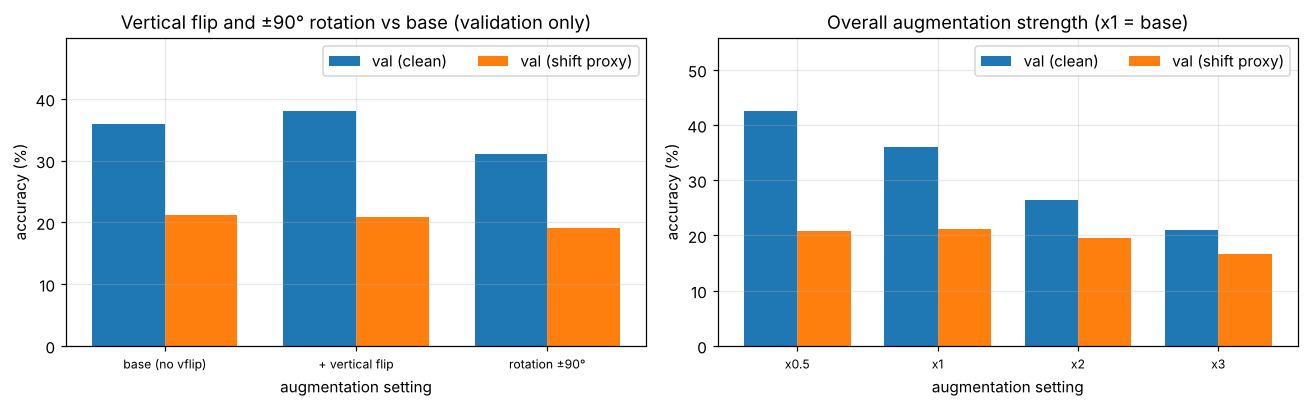

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); w = .38
def grouped(a, names, res, title):
    x = np.arange(len(names))
    a.bar(x-w/2, [100*res[n]['val_clean'] for n in names], w, label='val (clean)')
    a.bar(x+w/2, [100*res[n]['val_shift'] for n in names], w, label='val (shift proxy)')
    a.set_xticks(x); a.set_xticklabels(names, fontsize=8); a.set_ylabel('accuracy (%)'); a.set_xlabel('augmentation setting'); a.set_title(title); a.set_ylim(0, a.get_ylim()[1]*1.25); a.legend(loc='upper right', ncol=2)
names = ['base (no vflip)', '+ vertical flip', 'rotation ±90°']
grouped(ax[0], names, study, 'Vertical flip and ±90° rotation vs base (validation only)')
sn = [f'x{k}' for k in strength]; sres = {f'x{k}': v for k, v in strength.items()}
grouped(ax[1], sn, sres, 'Overall augmentation strength (x1 = base)')
plt.tight_layout(); plt.show()

### Answers to the Part B questions
(Numbers are validation accuracy, mean of 2 runs, from the study above; the validation set has only 100 images so differences of 1–2 points are within noise.)

**1. Would vertical flip help or hurt?** It should not help, and in principle it can hurt. CIFAR-10 objects have a fixed "up": sky above, ground below, wheels at the bottom of a car, legs below a horse. The test images are only rotated by up to ±25°, so upside-down pictures never occur. Training on them uses up some of the small network's capacity on orientations it will never be tested on, and it weakens cues like "blue region on top means airplane or bird". In my experiment adding vertical flip changed validation accuracy from 36.0% to 38.0% on clean images and from 21.2% to 20.8% on the shifted proxy. That is no real change either way, so I left it out (horizontal flip is a valid symmetry and I kept it).

**2. Rotation up to ±90° when the test only has ±25°.** The trade-off is *diversity versus relevance*. A wider range gives more variety and invariance to big rotations, but most of the augmented images are now rotations that never appear in the test, the network has to learn sideways and upside-down objects, and large rotations also put big black corners on the image. For a tiny model this wastes capacity and blurs orientation cues. Measured: ±90° gave 31.0% clean / 19.0% shifted-proxy, versus 36.0% / 21.2% with ±20°. A range close to the expected test range (a bit above it at most) is the sensible choice. The search below preferred ±15°; ±25° was almost as good.

**3. Why can too much augmentation reduce accuracy on such a small model?** The network only has about 89k parameters and sees 400 base images for at most 60 epochs. If the augmentation is too strong, the training images become very hard or even unrecognisable (an object can be almost fully erased or rotated and dimmed beyond recognition), so the model underfits and the training signal gets noisy, while the clean data it will actually be tested on looks different from what it practised on. In the strength sweep (all magnitudes multiplied by k) clean validation accuracy falls from 42.5% (x0.5) to 36.0% (x1), 26.5% (x2) and 21.0% (x3), and the shifted proxy also falls from x1 to x3 (21.2% → 16.7%). There is a sweet spot, and it is lower than "as much as possible".

## Part C – Regularisation and training design
Everything below is already in the model/training loop above. Placement and reasons:

* **BatchNorm** after every convolution (before the ReLU): keeps activations well scaled so a 3-module net trains stably with a high learning rate, and adds a little noise through batch statistics.
* **Dropout (p=0.5) only in the head, after the first fully connected layer.** The FC layer is where the network can memorise (it sees all pooled features at once). Early conv layers have few parameters, share weights across positions and carry neighbouring-pixel correlation, so dropping single activations there barely removes information (neighbours leak it back) and just makes the low-level features noisy. Global average pooling already removes the huge FC layers.
* **Weight decay** (AdamW, decoupled) on all weights: keeps the weights small, which acts as a prior against the sharp solutions that memorise 400 images.
* **Learning-rate schedule:** 3 warm-up epochs (BN + Adam are unstable in the first steps), then cosine decay so the last epochs make small, stable updates.
* **Label smoothing 0.1 (together with Mixup):** targets are never exactly 0/1, so the logits do not blow up; it reduces over-confidence, which matters because the shifted test images are out-of-distribution.
* **Early stopping:** the best-validation-accuracy weights are restored; training stops after 20 epochs without improvement.

The remaining numeric choices (weight decay, dropout rate) are picked on validation only below; the augmentation hyper-parameters are picked first.

In [17]:
print('--- stage 1: augmentation hyper-parameters of the final recipe (label smoothing 0.1 + Mixup always on) ---')
grid = []
for rot in [15, 25]:
    for cut in [0.2, 0.35]:
        for alpha in [0.2, 0.5]:
            c = AugCfg(geometric=True, photometric=True, cutout=True, mixup=True, smooth=0.1, rot=rot, cut_max=cut, mix_alpha=alpha)
            grid.append((dict(rot=rot, cut_max=cut, mix_alpha=alpha), val_score(f'rot {rot} cut {cut} mixup {alpha}', c)))
best1 = max(grid, key=lambda t: t[1]['score']); print('\nbest stage-1 setting:', best1[0], '-> score %.3f' % best1[1]['score'])
final_cfg = AugCfg(geometric=True, photometric=True, cutout=True, mixup=True, smooth=0.1, **best1[0])

print('\n--- stage 2: weight decay and dropout (augmentation fixed) ---')
hp_grid = []
for wd, dr in [(5e-4, 0.5), (5e-2, 0.5), (5e-4, 0.3), (5e-2, 0.3)]:
    hp_grid.append(((wd, dr), val_score(f'wd {wd} dropout {dr}', final_cfg, wd=wd, drop=dr)))
(best_wd, best_dr), r2 = max(hp_grid, key=lambda t: t[1]['score'])
final_hp = dict(wd=best_wd, drop=best_dr); print('\nchosen:', final_hp, '-> score %.3f' % r2['score'])

--- stage 1: augmentation hyper-parameters of the final recipe (label smoothing 0.1 + Mixup always on) ---


rot 15 cut 0.2 mixup 0.2           val clean 0.390 | val shifted-proxy 0.166 | score 0.278


rot 15 cut 0.2 mixup 0.5           val clean 0.390 | val shifted-proxy 0.204 | score 0.297


rot 15 cut 0.35 mixup 0.2          val clean 0.395 | val shifted-proxy 0.227 | score 0.311


rot 15 cut 0.35 mixup 0.5          val clean 0.350 | val shifted-proxy 0.198 | score 0.274


...

rot 25 cut 0.35 mixup 0.2          val clean 0.375 | val shifted-proxy 0.216 | score 0.295


rot 25 cut 0.35 mixup 0.5          val clean 0.345 | val shifted-proxy 0.193 | score 0.269

best stage-1 setting: {'rot': 15, 'cut_max': 0.35, 'mix_alpha': 0.2} -> score 0.311

--- stage 2: weight decay and dropout (augmentation fixed) ---


wd 0.05 dropout 0.5                val clean 0.370 | val shifted-proxy 0.225 | score 0.298


wd 0.0005 dropout 0.3              val clean 0.370 | val shifted-proxy 0.202 | score 0.286


wd 0.05 dropout 0.3                val clean 0.390 | val shifted-proxy 0.247 | score 0.319

chosen: {'wd': 0.05, 'drop': 0.3} -> score 0.319


In [18]:
sel = pd.DataFrame([dict(setting=r['label'], val_clean=100*r['val_clean'], val_shift_proxy=100*r['val_shift'], selection_score=100*r['score']) for _, r in grid + hp_grid]).round(1)
display(sel)
print('FINAL RECIPE ->', final_cfg, final_hp)

,setting,val_clean,val_shift_proxy,selection_score
0,rot 15 cut 0.2 mixup 0.2,39.0,16.6,27.8
1,rot 15 cut 0.2 mixup 0.5,39.0,20.4,29.7
2,rot 15 cut 0.35 mixup 0.2,39.5,22.7,31.1
3,rot 15 cut 0.35 mixup 0.5,35.0,19.8,27.4
4,rot 25 cut 0.2 mixup 0.2,39.0,18.0,28.5
5,rot 25 cut 0.2 mixup 0.5,37.0,17.4,27.2
6,rot 25 cut 0.35 mixup 0.2,37.5,21.6,29.5
7,rot 25 cut 0.35 mixup 0.5,34.5,19.3,26.9
8,wd 0.0005 dropout 0.5,39.5,22.7,31.1
9,wd 0.05 dropout 0.5,37.0,22.5,29.8


FINAL RECIPE -> {'vflip': 0.0, 'chswap': 0.0, 'geometric': True, 'photometric': True, 'cutout': True, 'mixup': True, 'rot': 15, 'scale': 0.1, 'pad': 4, 'flip': True, 'jit': 0.4, 'gray_p': 0.1, 'blur_p': 0.3, 'noise_p': 0.3, 'noise_max': 0.06, 'cut_p': 0.5, 'cut_max': 0.35, 'mix_alpha': 0.2, 'smooth': 0.1} {'wd': 0.05, 'drop': 0.3}


**Choices made on validation only.** The best augmentation setting was rotation ±15°, Cutout up to 35% of the area and Mixup α = 0.2. In stage 2, weight decay 0.05 with dropout 0.3 scored highest. The top few settings are only 1–2 points apart, which is inside the noise of a 100-image validation set, so I would not read too much into the exact winner; I simply followed the rule of letting validation decide. Learning rate (3e-3), batch size (32) and the schedule were set once at the start and not tuned further, to avoid overfitting the small validation set.

## Part D – Ablation study (3 seeds, mean ± std)
Each row adds one ingredient to the previous one. The first six rows use the same default magnitudes and the same optimiser settings, so only the augmentation changes. The last row is the final tuned recipe (Parts B/C). Test accuracies are only reported, not used for any decision.

In [19]:
abl = {
 'Geometric only (crop, flip, rotation)': AugCfg(geometric=True),
 'Photometric only (color jitter, blur, noise)': AugCfg(photometric=True),
 'Geometric + photometric': AugCfg(geometric=True, photometric=True),
 '+ Cutout / Random Erasing': AugCfg(geometric=True, photometric=True, cutout=True),
 '+ Mixup + label smoothing': AugCfg(geometric=True, photometric=True, cutout=True, mixup=True, smooth=0.1, mix_alpha=0.3),
}
for name, cfg in abl.items(): run_config(name, cfg)
_ = run_config('Final model', final_cfg, **final_hp)

[Geometric only (crop, flip, rotation)] seed 0: best epoch 51/60 | train 0.875 val 0.420 clean 0.432 shifted 0.162 | 52s


[Geometric only (crop, flip, rotation)] seed 1: best epoch 42/60 | train 0.775 val 0.450 clean 0.421 shifted 0.178 | 51s


[Geometric only (crop, flip, rotation)] seed 2: best epoch 44/60 | train 0.845 val 0.470 clean 0.429 shifted 0.158 | 51s


[Photometric only (color jitter, blur, noise)] seed 0: best epoch 36/56 | train 0.988 val 0.370 clean 0.384 shifted 0.175 | 49s


[Photometric only (color jitter, blur, noise)] seed 1: best epoch 23/43 | train 0.777 val 0.400 clean 0.371 shifted 0.173 | 39s


...

[+ Mixup + label smoothing] seed 1: best epoch 41/60 | train 0.485 val 0.380 clean 0.389 shifted 0.222 | 51s


[+ Mixup + label smoothing] seed 2: best epoch 22/42 | train 0.403 val 0.370 clean 0.330 shifted 0.181 | 37s


[Final model] seed 0: best epoch 43/60 | train 0.580 val 0.430 clean 0.412 shifted 0.241 | 52s


[Final model] seed 1: best epoch 47/60 | train 0.567 val 0.420 clean 0.415 shifted 0.236 | 51s


[Final model] seed 2: best epoch 47/60 | train 0.647 val 0.370 clean 0.420 shifted 0.222 | 50s


In [20]:
order = ['No augmentation'] + list(abl) + ['Final model']
table = pd.DataFrame([{ 'Configuration': n, 'Val Acc': mean_std([r['val'] for r in RES[n]]),
                        'Clean Test': mean_std([r['clean'] for r in RES[n]]), 'Shifted Test': mean_std([r['shifted'] for r in RES[n]]) } for n in order]).set_index('Configuration')
display(table)
mu = {n: np.mean([r['shifted'] for r in RES[n]]) for n in order}
print('\nChange in mean shifted-test accuracy when each ingredient is added (percentage points):')
steps = [('No augmentation','Geometric only (crop, flip, rotation)'), ('No augmentation','Photometric only (color jitter, blur, noise)'),
         ('Geometric only (crop, flip, rotation)','Geometric + photometric'), ('Geometric + photometric','+ Cutout / Random Erasing'),
         ('+ Cutout / Random Erasing','+ Mixup + label smoothing'), ('+ Mixup + label smoothing','Final model')]
for a, b in steps: print(f'  {a:<42} -> {b:<46} {100*(mu[b]-mu[a]):+.1f}')

,Val Acc,Clean Test,Shifted Test
Configuration,,,
No augmentation,42.3 ± 5.6,41.0 ± 1.3,15.3 ± 0.2
"Geometric only (crop, flip, rotation)",44.7 ± 2.1,42.7 ± 0.5,16.6 ± 0.9
"Photometric only (color jitter, blur, noise)",38.7 ± 1.2,39.0 ± 1.8,17.2 ± 0.3
Geometric + photometric,41.3 ± 0.9,42.3 ± 1.2,19.1 ± 0.8
+ Cutout / Random Erasing,40.0 ± 0.8,39.5 ± 1.4,22.3 ± 0.2
+ Mixup + label smoothing,38.7 ± 1.7,37.6 ± 3.3,20.6 ± 1.8
Final model,40.7 ± 2.6,41.6 ± 0.3,23.3 ± 0.8



Change in mean shifted-test accuracy when each ingredient is added (percentage points):
  No augmentation                            -> Geometric only (crop, flip, rotation)          +1.3
  No augmentation                            -> Photometric only (color jitter, blur, noise)   +1.9
  Geometric only (crop, flip, rotation)      -> Geometric + photometric                        +2.5
  Geometric + photometric                    -> + Cutout / Random Erasing                      +3.2
  + Cutout / Random Erasing                  -> + Mixup + label smoothing                      -1.7
  + Mixup + label smoothing                  -> Final model                                    +2.7


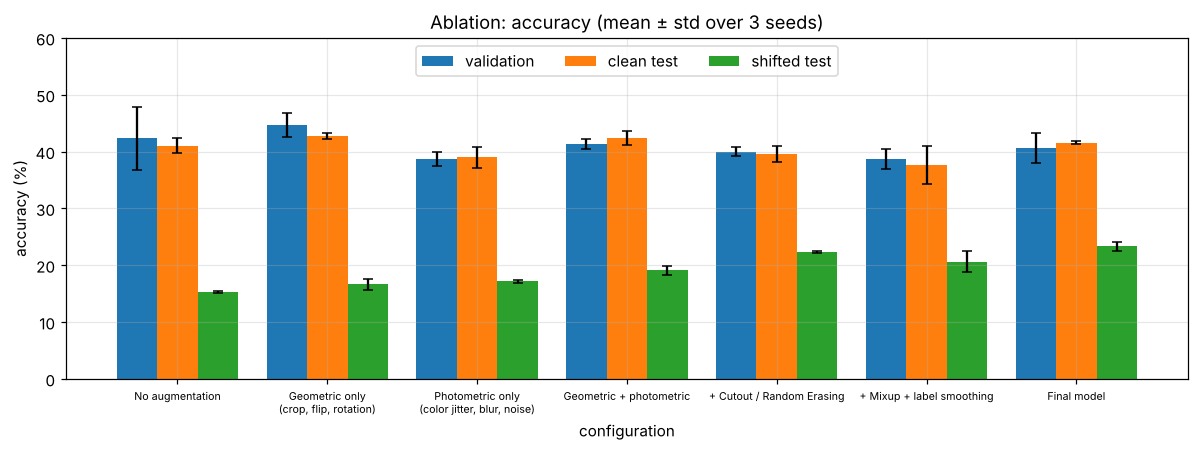

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.2)); x = np.arange(len(order)); w = .27
for k, (key, lab) in enumerate([('val', 'validation'), ('clean', 'clean test'), ('shifted', 'shifted test')]):
    m = [100*np.mean([r[key] for r in RES[n]]) for n in order]; s = [100*np.std([r[key] for r in RES[n]]) for n in order]
    ax.bar(x+(k-1)*w, m, w, yerr=s, capsize=3, label=lab)
ax.set_xticks(x); ax.set_xticklabels([n.replace(' (','\n(').replace('+ ','+ ') for n in order], fontsize=7); ax.set_ylabel('accuracy (%)'); ax.set_xlabel('configuration')
ax.set_title('Ablation: accuracy (mean ± std over 3 seeds)'); ax.set_ylim(0, 60); ax.legend(loc='upper center', ncol=3); plt.tight_layout(); plt.show()

### Reading the ablation table
Shifted-test accuracy (mean over 3 seeds): 15.3% (none) → 16.6% (geometric) / 17.2% (photometric) → 19.1% (both) → **22.3% (+ Cutout)** → 20.6% (+ Mixup + label smoothing) → **23.3% (final)**. Clean-test accuracy stays at about 40–42% throughout, so the shift robustness is gained without really losing clean accuracy.

**Largest gain from a single augmentation: Cutout / Random Erasing, +3.2 points** on top of geometric + photometric (19.1% → 22.3%, with a very small std of 0.2). It matches a specific corruption: the shifted test blanks out a rectangle covering about 25% of every image, and Cutout trains the network on exactly that kind of damage (a random rectangle of up to ~35% area is removed in half of the training images). The network learns to use several parts of the object instead of relying on one distinctive patch. Among the two single families, photometric (+1.9, covers brightness/contrast, blur and noise) was a bit more useful than geometric (+1.3, covers rotation) on its own, but both add up (+3.8 together).

**Mixup + label smoothing hurt slightly in the ablation row** (−1.7 points, and one seed was much worse). With α = 0.3 and only 60 epochs, a small network underfits when the images are already heavily augmented. After retuning on validation (smaller α = 0.2, weight decay 0.05, dropout 0.3) the final model gains +2.7 over that row. Overall the final recipe improves the shifted test by about 8 points over the baseline, and the largest individual contribution was Cutout.

## Part E – Error analysis (final model)
Per-class accuracy and the confusion matrix use the **final model, seed 0**, on the shifted test set (and the no-augmentation baseline for comparison in the bar plot).

class         airplane  automobile  bird   cat  deer   dog  frog  horse  ship  truck
baseline (%)      13.4        18.0  12.3  22.0  11.9  20.9   4.5    7.4  24.9   15.5
final (%)         20.3        38.3  23.6  22.5   7.5  34.9  21.3   19.8  41.5   11.4


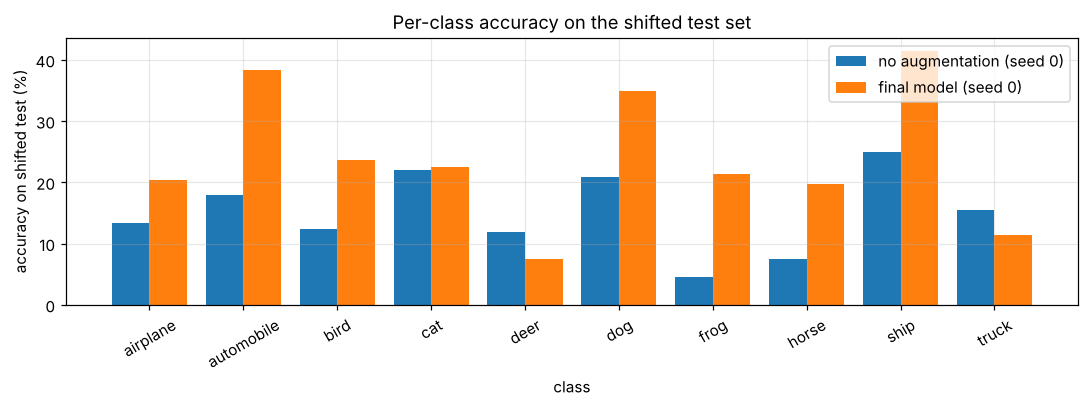

In [22]:
final_m = RES['Final model'][0]['model']; base_m = RES['No augmentation'][0]['model']
P = predict(final_m, Xshift); pred = P.argmax(1); Pb = predict(base_m, Xshift).argmax(1)
pc  = [(pred[Yshift==c]==c).float().mean().item() for c in range(10)]
pcb = [(Pb[Yshift==c]==c).float().mean().item() for c in range(10)]
print(pd.DataFrame({'class': CLASSES, 'baseline (%)': np.round(100*np.array(pcb),1), 'final (%)': np.round(100*np.array(pc),1)}).set_index('class').T.to_string())
fig, ax = plt.subplots(figsize=(10, 3.8)); x = np.arange(10)
ax.bar(x-.2, 100*np.array(pcb), .4, label='no augmentation (seed 0)'); ax.bar(x+.2, 100*np.array(pc), .4, label='final model (seed 0)')
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=30); ax.set_xlabel('class'); ax.set_ylabel('accuracy on shifted test (%)'); ax.set_title('Per-class accuracy on the shifted test set'); ax.legend(); plt.tight_layout(); plt.show()

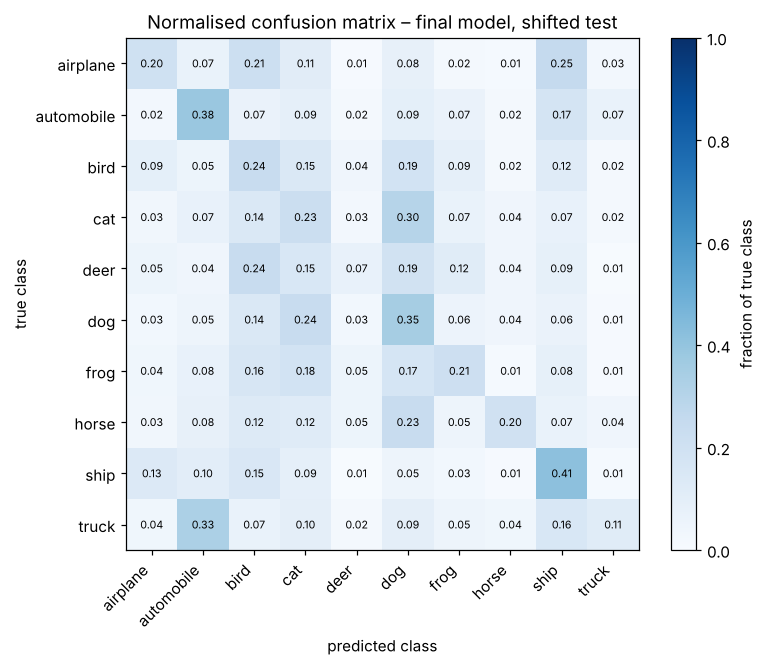

Most frequent confusions (true -> predicted, share of the true class):
       truck -> automobile 33.0%
         cat -> dog        30.0%
    airplane -> ship       25.3%
         dog -> cat        23.6%
        deer -> bird       23.6%
       horse -> dog        23.5%
    airplane -> bird       21.5%
        deer -> dog        19.3%


In [23]:
cm = confusion_matrix(Yshift.numpy(), pred.numpy(), normalize='true')
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1); plt.colorbar(im, label='fraction of true class')
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha='right'); ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10): ax.text(j, i, f'{cm[i,j]:.2f}', ha='center', va='center', fontsize=7, color='white' if cm[i,j] > .5 else 'black')
ax.set_xlabel('predicted class'); ax.set_ylabel('true class'); ax.set_title('Normalised confusion matrix – final model, shifted test'); ax.grid(False); plt.tight_layout(); plt.show()
off = [(cm[i,j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j]
print('Most frequent confusions (true -> predicted, share of the true class):')
for v, a, b in sorted(off, reverse=True)[:8]: print(f'  {a:>10} -> {b:<10} {100*v:.1f}%')

### Per-class accuracy and confusions
On the shifted test the final model is best on **ship (41.5%)**, **automobile (38.3%)** and **dog (34.9%)**, and worst on **deer (7.5%)** and **truck (11.4%)**. Compared with the baseline, automobile, ship, frog, horse and dog improve a lot, while deer and truck actually got worse.

Most confused pairs (share of the true class):
* **truck → automobile (33%)**: both are road vehicles with wheels, windshields and similar road backgrounds; at 32×32 the main difference is size and the trailer/cargo box, and an occluding box often hides exactly that part.
* **cat ↔ dog (30% and 24%)**: the classic one. Similar fur texture, body pose, ears and indoor backgrounds, and the fine details that separate them (snout, ear shape) are lost at this resolution and by blur, noise and occlusion.
* **airplane → ship (25%)**: both are long, rigid, smooth objects against a uniform blue-ish background (sky or sea). After brightness change and channel swapping the "sky is blue" cue is not reliable any more.
* **deer → bird (24%), horse → dog (23%)**: animals on grass or brown backgrounds with the legs, head or antlers partly hidden look alike to a small network.

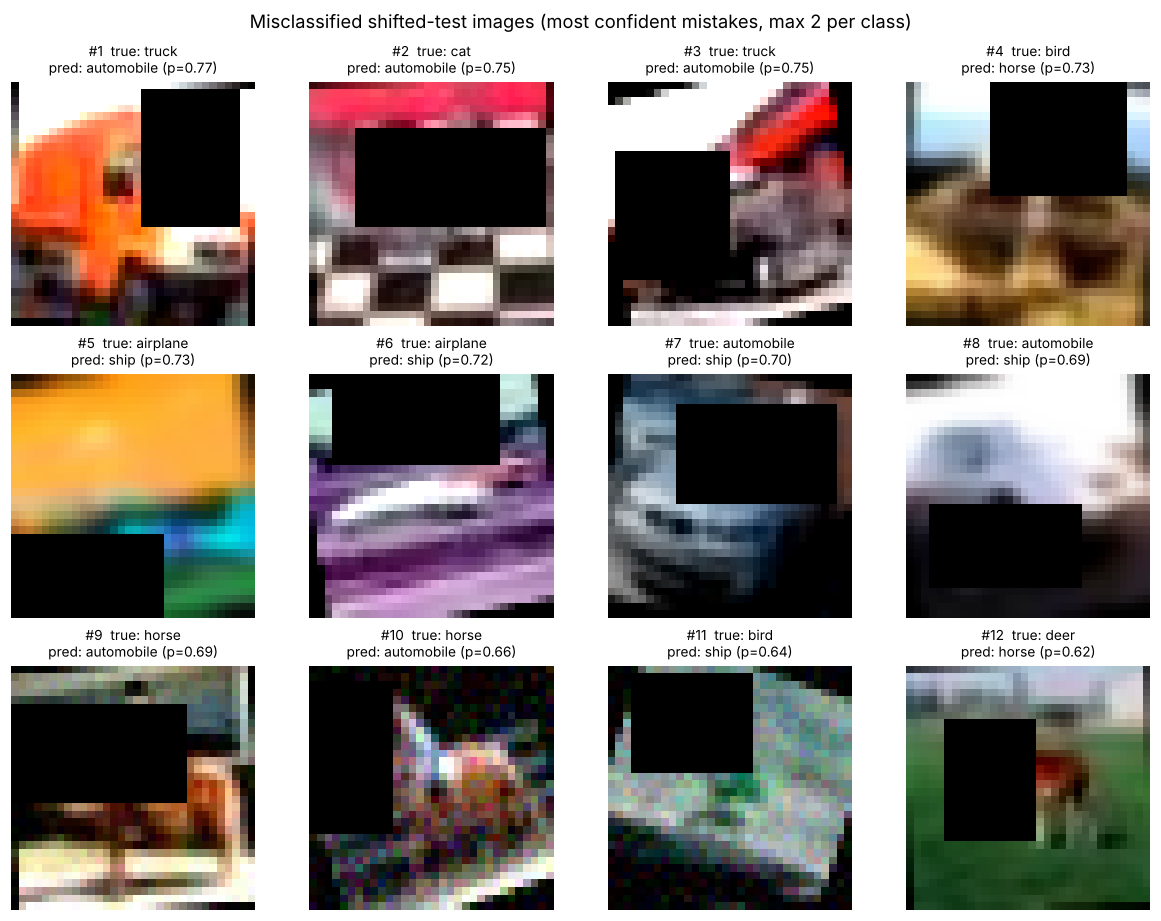

,true,pred,rot(deg),bright,contrast,ch.swap,blur,noise,occluded %
#,,,,,,,,,
1,truck,automobile,-3.3,1.25,1.37,False,False,False,23.0
2,cat,automobile,2.4,0.98,1.30,False,False,False,32.0
3,truck,automobile,12.2,1.44,1.29,True,False,False,25.0
4,bird,horse,-5.0,1.04,1.48,False,True,False,26.0
5,airplane,ship,8.1,1.11,1.43,True,True,False,21.0
6,airplane,ship,10.0,1.42,1.47,True,False,False,26.0
7,automobile,ship,-10.5,0.79,1.31,False,False,False,27.0
8,automobile,ship,9.7,1.12,1.27,False,True,False,21.0
9,horse,automobile,4.3,0.92,1.40,False,False,True,29.0


In [24]:
# misclassified images: take the most confidently wrong ones, at most 2 per true class, 12 in total
conf = P.max(1).values; wrong = torch.where(pred != Yshift)[0]
wrong = wrong[torch.argsort(conf[wrong], descending=True)]
chosen, cnt = [], {}
for i in wrong.tolist():
    t = int(Yshift[i]); 
    if cnt.get(t, 0) < 2: chosen.append(i); cnt[t] = cnt.get(t, 0) + 1
    if len(chosen) == 12: break
fig, ax = plt.subplots(3, 4, figsize=(11, 8.5))
for a, i in zip(ax.ravel(), chosen):
    a.imshow(Xshift[i].permute(1,2,0)); a.axis('off')
    a.set_title(f"#{chosen.index(i)+1}  true: {CLASSES[Yshift[i]]}\npred: {CLASSES[pred[i]]} (p={conf[i]:.2f})", fontsize=9)
fig.suptitle('Misclassified shifted-test images (most confident mistakes, max 2 per class)'); plt.tight_layout(); plt.show()
if INFO is not None:
    d = pd.DataFrame({'#': range(1, len(chosen)+1), 'true': [CLASSES[Yshift[i]] for i in chosen], 'pred': [CLASSES[pred[i]] for i in chosen],
        'rot(deg)': [round(float(INFO['rot'][i]),1) for i in chosen], 'bright': [round(float(INFO['bright'][i]),2) for i in chosen], 'contrast': [round(float(INFO['contrast'][i]),2) for i in chosen],
        'ch.swap': [bool(INFO['swap'][i]) for i in chosen], 'blur': [bool(INFO['blur'][i]) for i in chosen], 'noise': [bool(INFO['noise'][i]) for i in chosen],
        'occluded %': [round(100*float(INFO['occ_area'][i]),0) for i in chosen]}).set_index('#')
    display(d)

### Why these 12 images failed
These are the most confident wrong predictions (at most 2 per true class). The table above gives the exact corruption applied to each one.

1. **truck → automobile.** The box hides the trailer, and the visible orange cab with a windshield looks like a car front. Brightness 1.25 and contrast 1.37 also wash out the details.
2. **cat → automobile.** The largest occlusion (32%) hides almost the whole animal. What is left is a red band and a black-and-white checked pattern, which resembles a car body and grille. No cat part (face, ears) is visible at all.
3. **truck → automobile.** Rotated by 12° with the channel swap, so the colours are unnatural, and the box hides the lower left. The remaining bright red shape looks like a car body.
4. **bird → horse.** The box covers the area where the head and beak should be, which are the main bird cues. The remaining brown textured body looks like a horse body.
5. **airplane → ship.** The channel swap turned the sky orange and a blue/cyan band appears at the bottom, which reads as water. With blur, the thin plane shape is lost and a "ship on water" scene is what remains.
6. **airplane → ship.** The sky is purple after the channel swap and the white fuselage seen at an angle looks like a ship hull. The model relies on blue-sky colour for airplanes and that cue is gone.
7. **automobile → ship.** Darkened (0.79), rotated by −10°, and the box covers the roof and windshield. The grey-blue body with the dark corners looks like a hull.
8. **automobile → ship.** An over-exposed, blurred white car on a white background; the box covers the wheels, which are the strongest car cue. A white blob is read as a ship hull in haze.
9. **horse → automobile.** Noise plus a box that covers most of the body. The visible part is a bright striped background (fence or ground), which looks like man-made structure.
10. **horse → automobile.** Rotated 18° with heavy noise. The surviving region is dominated by speckle, so texture and shape cues are destroyed and the network falls back to a "man-made object" guess.
11. **bird → ship.** The scene is noisy, dark (0.74), rotated by −18° and channel-swapped. The grey-white speckled texture has no clear object shape and resembles water or a hull.
12. **deer → horse.** Dark image (0.72) and the box covers part of the body. What remains is a four-legged brown animal on grass, and deer and horse share this shape and context. The antlers, which separate them, are not visible.

**Common pattern.** The mistakes are driven by three things: the large black occlusion box removing the part that identifies the class (head, wheels, trailer), colour changes (channel swap, brightness) breaking the colour cues, and noise or blur removing texture. Also, the network is often **confidently wrong** (p of 0.6–0.8) when a big black box fills the image. My Cutout fills with random colours, while the test box is black, so the network has never seen large pure-black regions; filling with a mix of random colours and black would be a sensible improvement.

,clean test,channel-swap only,drop (pts)
model,,,
No augmentation,41.0 ± 1.3,31.2 ± 0.6,9.8
Geometric + photometric,42.3 ± 1.2,28.9 ± 1.0,13.5
Final model,41.6 ± 0.3,29.6 ± 0.5,12.0


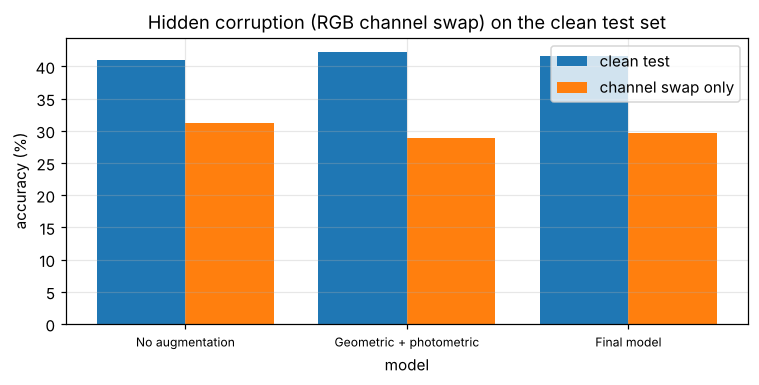

In [25]:
# Hidden-corruption test: apply ONLY the channel swap (to every image) to the clean test set
g = torch.Generator().manual_seed(5); Xswap, swapped = channel_swap(Xclean, 1.0, g)
rows = []
for n in ['No augmentation', 'Geometric + photometric', 'Final model']:
    c = [r['clean'] for r in RES[n]]; s = [acc(r['model'], Xswap, Yclean) for r in RES[n]]
    rows.append({'model': n, 'clean test': mean_std(c), 'channel-swap only': mean_std(s), 'drop (pts)': round(100*(np.mean(c)-np.mean(s)), 1)})
hid = pd.DataFrame(rows).set_index('model'); display(hid)
fig, ax = plt.subplots(figsize=(7, 3.6)); x = np.arange(len(rows))
ax.bar(x-.2, [float(r['clean test'].split(' ')[0]) for r in rows], .4, label='clean test'); ax.bar(x+.2, [float(r['channel-swap only'].split(' ')[0]) for r in rows], .4, label='channel swap only')
ax.set_xticks(x); ax.set_xticklabels([r['model'] for r in rows], fontsize=8); ax.set_xlabel('model'); ax.set_ylabel('accuracy (%)'); ax.set_title('Hidden corruption (RGB channel swap) on the clean test set'); ax.legend(); plt.tight_layout(); plt.show()

### Hidden-corruption test (channel swap only)
Applying only the channel swap (every image, clean test set) lowers accuracy from about 41–42% to about 29–31% for all three models. The baseline drops 9.8 points and the final model 12.0 points, so **the augmentation did not generalise to this corruption**. That makes sense: my augmentation only changes saturation, brightness/contrast and sometimes converts to grayscale, and none of that changes the *order* of the colour channels. The network learned that colour layout is informative (blue top for sky and sea, green for grass, ...) and swapping the channels moves the images away from anything it has seen. It is also a reminder that the improvement from the augmentation (about +8 points on the shifted test) comes from the corruptions I did cover (occlusion, brightness/contrast, noise, rotation) and not from a general robustness.

In [26]:
# Diagnostic follow-up (NOT used for any selection, the final model above stays as chosen on validation):
# what happens if colour-order shuffling is simply added to the final recipe?
cs = copy.copy(final_cfg); cs.chswap = 0.3
_ = run_config('Final recipe + channel shuffle (diagnostic)', cs, **final_hp)
n = 'Final recipe + channel shuffle (diagnostic)'
hid2 = pd.DataFrame([{'model': m, 'clean test': mean_std([r['clean'] for r in RES[m]]), 'shifted test': mean_std([r['shifted'] for r in RES[m]]),
                      'channel-swap only': mean_std([acc(r['model'], Xswap, Yclean) for r in RES[m]])} for m in ['Final model', n]]).set_index('model'); display(hid2)

[Final recipe + channel shuffle (diagnostic)] seed 0: best epoch 48/60 | train 0.515 val 0.370 clean 0.403 shifted 0.244 | 51s


[Final recipe + channel shuffle (diagnostic)] seed 1: best epoch 59/60 | train 0.555 val 0.440 clean 0.415 shifted 0.227 | 51s


[Final recipe + channel shuffle (diagnostic)] seed 2: best epoch 46/60 | train 0.530 val 0.420 clean 0.407 shifted 0.233 | 50s


,clean test,shifted test,channel-swap only
model,,,
Final model,41.6 ± 0.3,23.3 ± 0.8,29.6 ± 0.5
Final recipe + channel shuffle (diagnostic),40.8 ± 0.5,23.5 ± 0.7,36.2 ± 1.0


**Follow-up (diagnostic only, not part of the model selection).** To check the explanation, I added random channel shuffling (p = 0.3) to the final recipe. Accuracy with only the swap applied rises from 29.6% to 36.2% (+6.6 points) at a small cost on clean data (41.6% → 40.8%), so the drop really was a missing invariance. On the full shifted test the gain is only +0.2 points (23.3% → 23.5%), because only about half of the shifted images are channel-swapped and the other corruptions (mainly the large box) cause most of the errors. I did not use this model as the final one: validation never saw this corruption, and choosing it would mean tuning to knowledge of the test pipeline. If the real hidden corruption is a channel swap or grayscale, this is a one-line change worth making.

## Part F – Test-time augmentation (bonus)
For each test image I average the softmax over N deterministic copies: the original, a horizontal flip, and ±2 pixel shifts (with and without flip). Reported for the final model (3 seeds), on the shifted test set. Inference cost is wall-clock time for the 10,000 images; it grows linearly with N because every copy needs a full forward pass.

,shifted-test acc (%),change vs N=1 (pts),time for 10k imgs (s),ms / image,cost vs N=1
N copies,,,,,
1,23.3 ± 0.8,0.00,6.51,0.651,1.0x
2,23.4 ± 0.8,0.13,13.13,1.313,2.0x
4,23.5 ± 0.7,0.22,25.65,2.565,3.9x
8,23.5 ± 0.7,0.21,52.76,5.276,8.1x


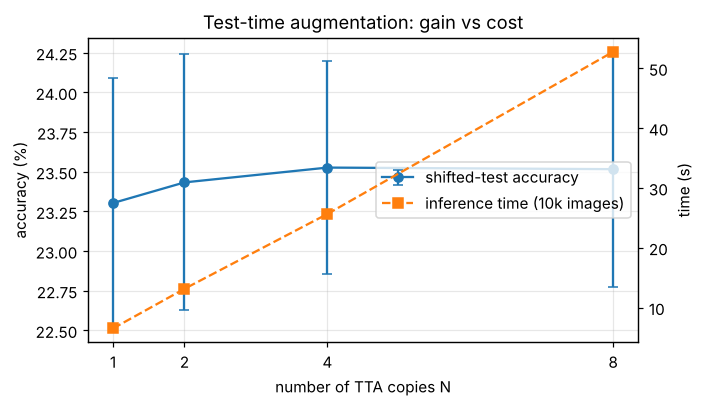

In [27]:
def shift_img(x, dx, dy, p=2):
    xp = F.pad(x, (p,)*4, mode='reflect'); H, W = x.shape[2:]
    return xp[:, :, p+dy:p+dy+H, p+dx:p+dx+W]
TTA = [lambda x: x, lambda x: x.flip(3), lambda x: shift_img(x, 2, 0), lambda x: shift_img(x, -2, 0),
       lambda x: shift_img(x, 0, 2), lambda x: shift_img(x, 0, -2), lambda x: shift_img(x.flip(3), 2, 2), lambda x: shift_img(x.flip(3), -2, -2)]
def predict_tta(m, x, n): return sum(predict(m, TTA[k](x)) for k in range(n)) / n

Ns = [1, 2, 4, 8]; tta_acc = {n: [] for n in Ns}; tta_time = {n: [] for n in Ns}
for r in RES['Final model']:
    for n in Ns:
        t0 = time.perf_counter(); p = predict_tta(r['model'], Xshift, n); tta_time[n].append(time.perf_counter()-t0)
        tta_acc[n].append((p.argmax(1) == Yshift).float().mean().item())
tta = pd.DataFrame([{'N copies': n, 'shifted-test acc (%)': mean_std(tta_acc[n]), 'change vs N=1 (pts)': round(100*(np.mean(tta_acc[n])-np.mean(tta_acc[1])), 2),
                     'time for 10k imgs (s)': round(np.mean(tta_time[n]), 2), 'ms / image': round(1000*np.mean(tta_time[n])/10000, 3), 'cost vs N=1': f'{np.mean(tta_time[n])/np.mean(tta_time[1]):.1f}x'} for n in Ns]).set_index('N copies')
display(tta)
fig, ax = plt.subplots(figsize=(6.5, 3.8)); ax2 = ax.twinx()
l1 = ax.errorbar(Ns, [100*np.mean(tta_acc[n]) for n in Ns], yerr=[100*np.std(tta_acc[n]) for n in Ns], marker='o', capsize=3, c='C0', label='shifted-test accuracy')
l2, = ax2.plot(Ns, [np.mean(tta_time[n]) for n in Ns], marker='s', c='C1', ls='--', label='inference time (10k images)')
ax.set_xlabel('number of TTA copies N'); ax.set_ylabel('accuracy (%)'); ax2.set_ylabel('time (s)'); ax.set_xticks(Ns); ax.set_title('Test-time augmentation: gain vs cost'); ax2.grid(False)
ax.legend([l1, l2], ['shifted-test accuracy', 'inference time (10k images)'], loc='center right'); plt.tight_layout(); plt.show()

### TTA result
Averaging 8 augmented copies changes the shifted-test accuracy from 23.3% to 23.5% (+0.2 points). That is smaller than the seed-to-seed std (about ±0.7), so there is **no meaningful gain**, while the inference cost grows almost linearly with N (about 7.8× slower for N = 8 on this CPU, from 0.69 to 5.4 ms per image). Flips and ±2 px shifts only cover small geometric changes, but the main failures on this test set are caused by occlusion, colour changes and noise, which these copies do not fix. For this model TTA is not worth its cost.

## Final summary

In [28]:
fin = RES['Final model']
summary = dict(seed_info=dict(global_seed=GLOBAL_SEED, train_seeds=SEEDS), params=n_params(net), final_cfg={k: v for k, v in final_cfg.__dict__.items()}, final_hp=final_hp,
    final_shifted_test=mean_std([r['shifted'] for r in fin]), final_clean_test=mean_std([r['clean'] for r in fin]), final_val=mean_std([r['val'] for r in fin]),
    baseline_shifted_test=mean_std([r['shifted'] for r in RES['No augmentation']]), final_shifted_with_TTA8=mean_std(tta_acc[8]))
best_step = max(steps, key=lambda t: mu[t[1]]-mu[t[0]])
summary['largest_single_gain'] = f"{best_step[0]} -> {best_step[1]} ({100*(mu[best_step[1]]-mu[best_step[0]]):+.1f} pts shifted-test)"
print(json.dumps(summary, indent=1, default=str)); json.dump(summary, open('results_summary.json', 'w'), indent=1, default=str)
table.to_csv('ablation_table.csv')

{
 "seed_info": {
  "global_seed": 42,
  "train_seeds": [
   0,
   1,
   2
  ]
 },
 "params": 88754,
 "final_cfg": {
  "vflip": 0.0,
  "chswap": 0.0,
  "geometric": true,
  "photometric": true,
  "cutout": true,
  "mixup": true,
  "rot": 15,
  "scale": 0.1,
  "pad": 4,
  "flip": true,
  "jit": 0.4,
  "gray_p": 0.1,
  "blur_p": 0.3,
  "noise_p": 0.3,
  "noise_max": 0.06,
  "cut_p": 0.5,
  "cut_max": 0.35,
  "mix_alpha": 0.2,
  "smooth": 0.1
 },
 "final_hp": {
  "wd": 0.05,
  "drop": 0.3
 },
 "final_shifted_test": "23.3 \u00b1 0.8",
 "final_clean_test": "41.6 \u00b1 0.3",
 "final_val": "40.7 \u00b1 2.6",
 "baseline_shifted_test": "15.3 \u00b1 0.2",
 "final_shifted_with_TTA8": "23.5 \u00b1 0.7",
 "largest_single_gain": "Geometric + photometric -> + Cutout / Random Erasing (+3.2 pts shifted-test)"
}


### Summary
* **Final model:** 3 Inception modules + LeNet-style stem + global average pooling, 88,754 parameters, trained from scratch on 400 images.
* **Final test score (3 seeds):** shifted test **23.3 ± 0.8%**, clean test 41.6 ± 0.3% (baseline without augmentation: 15.3 ± 0.2% shifted, 41.0 ± 1.3% clean).
* **Configuration:** geometric + photometric augmentation, Cutout (up to 35% area), Mixup (α = 0.2) with label smoothing 0.1, rotation ±15°, AdamW (lr 3e-3, weight decay 0.05), cosine schedule with warm-up, dropout 0.3 after the first FC layer, early stopping on validation accuracy.
* **Single change that helped the most:** Cutout / Random Erasing (+3.2 points on the shifted test), because the shifted test hides about 25% of each image.
* **Limits:** absolute shifted accuracy is still low (about 23%); the model does not generalise to the channel-swap corruption; TTA gave no useful gain. The shifted test here is my own simulation of the pipeline described in the task, so absolute numbers on the official file may differ.